# Barycentric Guidance with FLUX.2 [klein] 4B

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/harveymannering/BarycentricGuidance/blob/main/notebooks/barycentric_guidance_klein.ipynb) [![arXiv](https://img.shields.io/badge/arXiv-2610.16892-b31b1b.svg)](https://arxiv.org/abs/2610.16892)

Edits a CelebA-HQ face to a 5×5 grid of valence–arousal targets using the full method: barycentric guidance with face-morph refinement and default settings. FLUX.2 [klein] 4B needs roughly 17 GB of GPU memory in bf16 (e.g. a Colab L4 or A100). For other editors, change the model name to `'flux2-dev'`, `'flux2-klein'` or `'qwen-2511'`; these need much larger GPUs.

On Colab, the first cell clones the repository and installs the requirements. To run locally instead, start Jupyter from the `notebooks/` directory; the first cell then does nothing.

In [ ]:
import sys
if 'google.colab' in sys.modules:  # on Colab: fetch the code and install requirements
    !git clone https://github.com/harveymannering/BarycentricGuidance
    %cd BarycentricGuidance/notebooks
    !pip install --quiet -r ../requirements.txt

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/422 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

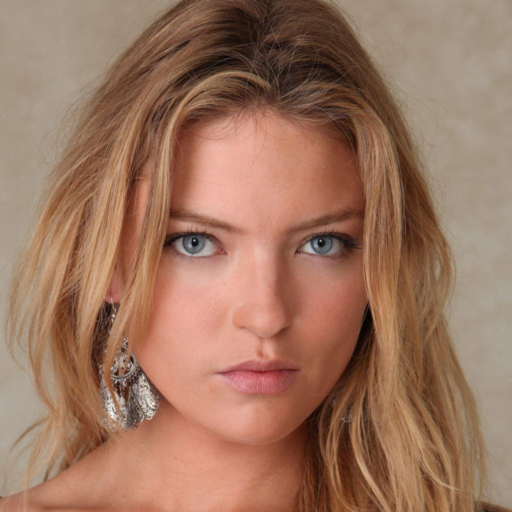

In [2]:
import argparse
import sys
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display

sys.path.insert(0, '../src')  # the code lives in src/
from dataset import load_image
from guidance import edit_va
from pipelines import load_editor
from utils import load_va_mesh, set_seed

set_seed(0)
editor = load_editor('flux2-klein-4b', cache_dir=None, device=torch.device('cuda'))
_, points, tri, prompts = load_va_mesh()
args = argparse.Namespace(mode='bary_guide', morph=True, scale_w_cfg=True, guidance_scale=4.0,
                          morph_step=10, anchor_steps=30, inference_steps=30)
source = load_image('celeba_example.jpg')
source

In [5]:
vals = np.linspace(-1, 1, 5)
images, cache = {}, {}  # cache reuses anchor emotion edits across the grid
for a in vals[::-1]:
    for v in vals:
        images[v, a], cache = edit_va(editor, source, np.array([v, a]), points, tri, prompts, args,
                                      seed=0, emotion_cache=cache)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

... (25 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

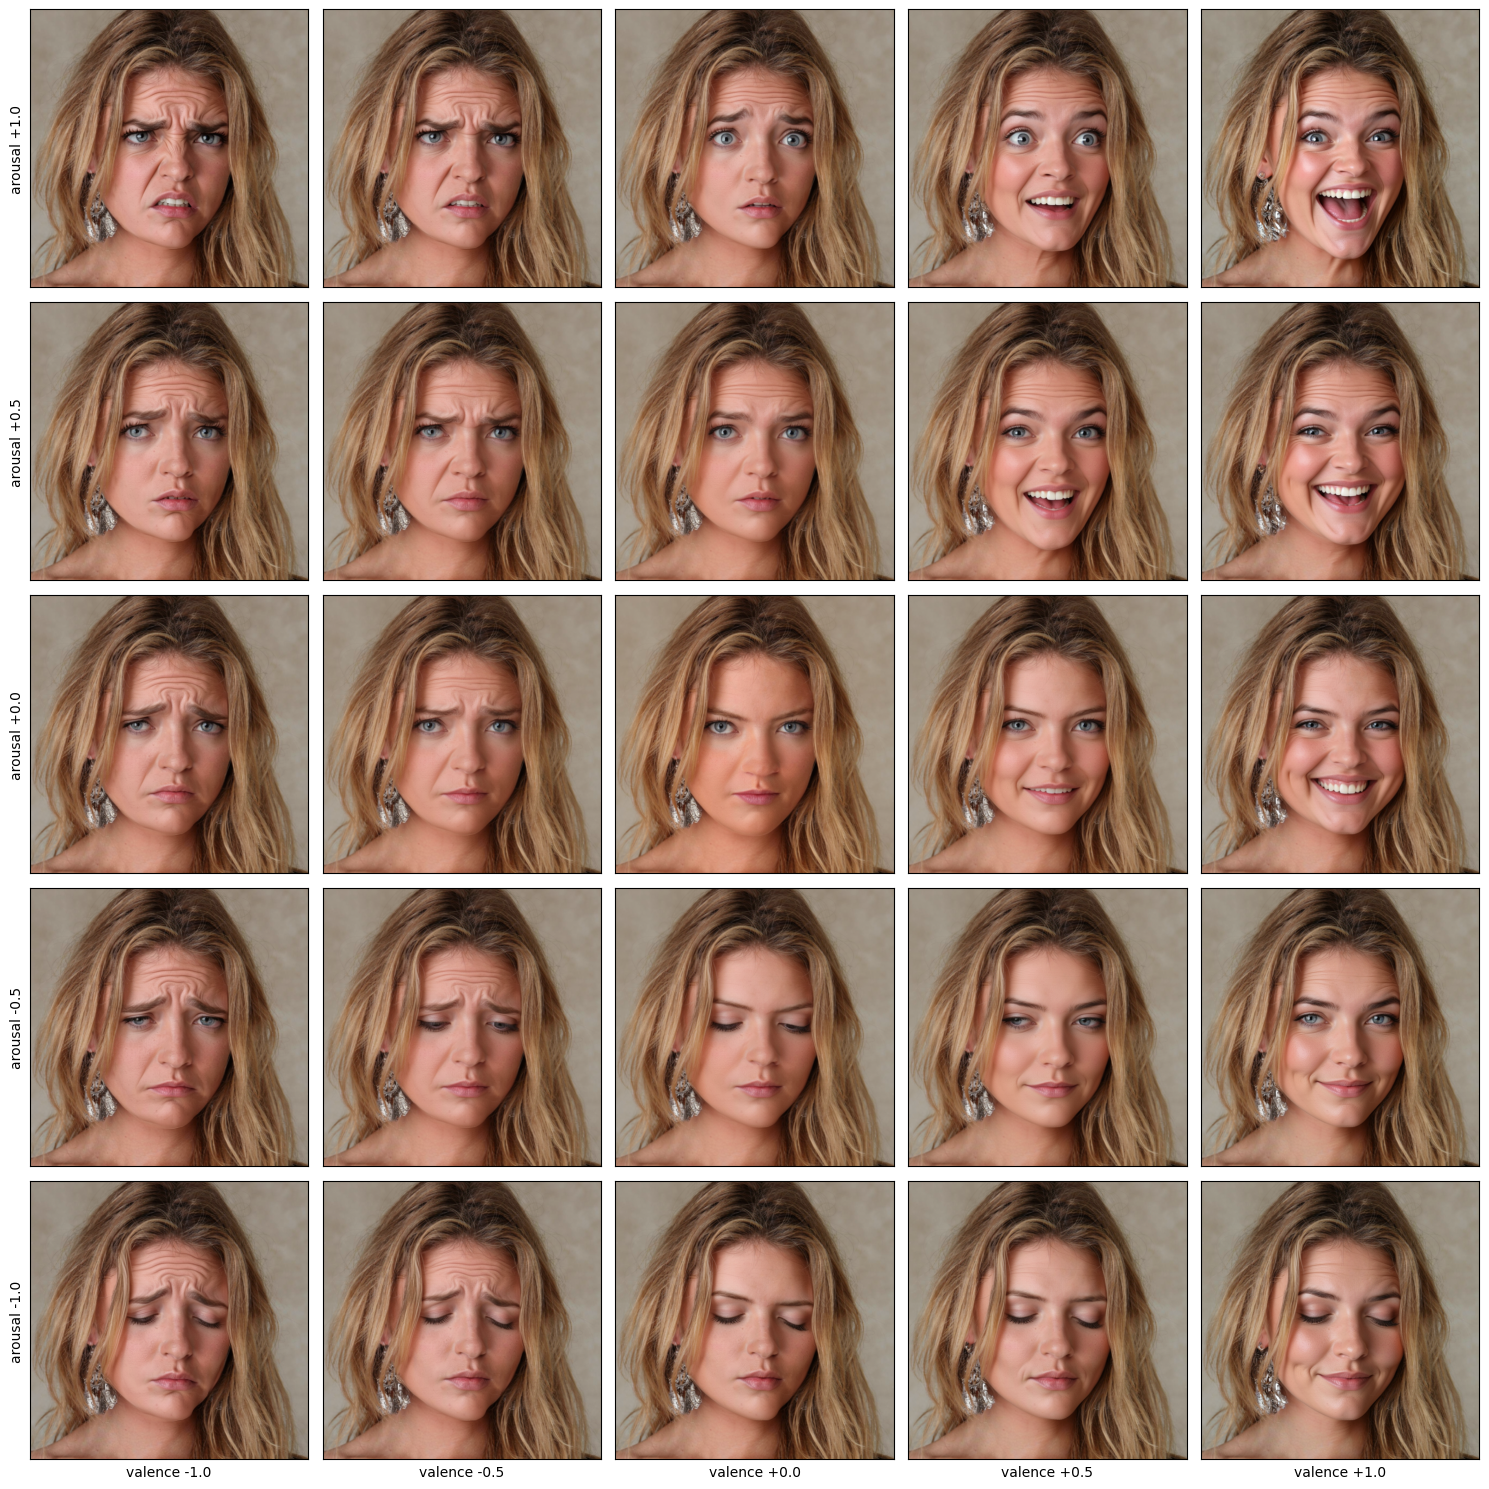

In [6]:
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
for r, a in enumerate(vals[::-1]):
    for c, v in enumerate(vals):
        ax = axes[r, c]
        ax.imshow(images[v, a])
        ax.set_xticks([]); ax.set_yticks([])
        if r == 4: ax.set_xlabel(f'valence {v:+.1f}')
        if c == 0: ax.set_ylabel(f'arousal {a:+.1f}')
plt.tight_layout()